## Inspect trained L1 ADAGE models

### November 1, 2026

### Mukundan Thanigaivelan

In this notebook, we take a look at the trained 50 models and see if any of them are good.

**Need to fix Google Drive Issue and Save Models, Loss History, KEGG Matrices, and all Plots!**

### Load libraries

In [33]:
# Prepend the correct prefix to load modules from adage/
import sys, os, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent))

In [34]:
from m_adage import Adage, LinkedAE

from pandas import read_csv
import numpy as np
from sklearn.metrics import mean_squared_error
from tensorflow import zeros

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from json import load
from zipfile import ZipFile
from types import SimpleNamespace

### Load models

In [35]:
model_filenames = [
  f'../data/ec_L1_model_{i+1}.keras'
  for i in range(50)
]

In [36]:
# Load hyperparameters
with open('../data/ec_L1_model_hps.json', 'r') as f:
  optimal_hps = load(f)

In [37]:
train_comp = read_csv('../data/ecmg_lcn01_medmean_normal_muk.csv', index_col = 0)
loaded_models = []

for i, file in enumerate(model_filenames):
  # Create autoencoder object
  ae = LinkedAE.LinkedAE(
    input_dim = train_comp.shape[0],
    encoding_dim = optimal_hps['units'],
    act1 = optimal_hps['act1'],
    act2 = optimal_hps['act2'],
    dropout = optimal_hps['dropout'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    init = optimal_hps['init'],
    tied = optimal_hps['tied']
  )
  ae(zeros((1, train_comp.shape[0])))

  # Pull model weights
  with ZipFile(file) as z:
    z.extract('model.weights.h5')

  # Load saved weights
  ae.load_weights('model.weights.h5')

  # Delete extracted weights file
  os.remove('model.weights.h5')
  
  # Create ADAGE object
  adage = Adage.Adage(
    autoencoder = ae,
    history = SimpleNamespace(
      history = {
        'loss': np.loadtxt(
                  f'../data/ec_L1_model_loss_{i+1}.csv',
                  delimiter=','
                ).reshape(-1).tolist(),
        'val_loss': np.loadtxt(
                      f'../data/ec_L1_model_val_loss_{i+1}.csv',
                      delimiter=','
                    ).reshape(-1).tolist()
      }
    ),
    train_comp = train_comp
  )

  # Add model to list
  loaded_models.append(adage)

In [38]:
len(loaded_models)

50

### Reconstruction Error

In [39]:
x_train = train_comp.values.astype("float64").T
reconstruct_errors = []

for model in loaded_models:
  x_pred = model.autoencoder.predict(x_train, verbose = 0)
  mse = mean_squared_error(x_train.flatten(), x_pred.flatten())
  reconstruct_errors.append(mse)

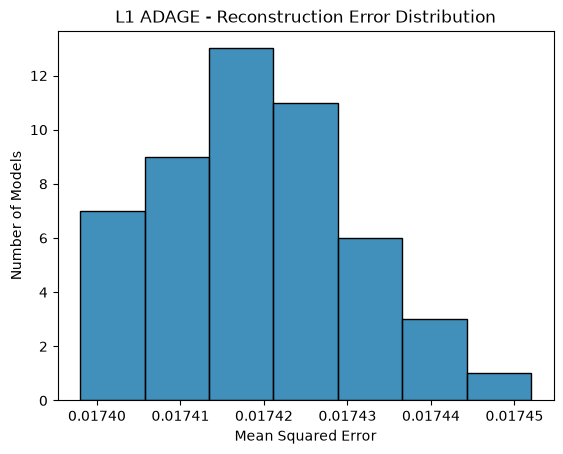

In [41]:
# Plot distribution of reconstruction error across models
ax = sns.histplot(reconstruct_errors)

plt.title("L1 ADAGE - Reconstruction Error Distribution")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Models")

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins = 6))

# Save plot locally
plot_path = '../data/ec_L1_recon_err.png'
plt.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/L1 Models/plots/'

### KEGG Enrichment

In [42]:
# Create enrichment matrices
kegg_dfs = []

for model in loaded_models:
  ec_kegg_ps = model.set_kegg('../data/filtered_ec_kegg_pathways.tsv')
  kegg_dfs.append(ec_kegg_ps)

In [43]:
# Save sum of p-values across each matrix to lists
p_val_sums = []

for df in kegg_dfs:
  p_val_sums.append(df.sum().sum())

In [44]:
# Inspect p-values
p_val_sums

[np.float64(23.149186813817447),
 np.float64(24.061803239263483),
 np.float64(29.420403459837612),
 np.float64(16.149153927372982),
 np.float64(16.23898491360373),
 np.float64(25.714118564488693),
 np.float64(21.316866962298437),
 np.float64(9.099996186394606),
 np.float64(10.933255198482447),
 np.float64(11.787313518943707),
 np.float64(27.203806250001048),
 np.float64(6.032977291464178),
 np.float64(21.186054007014814),
 np.float64(22.40958115672891),
 np.float64(23.574323552610515),
 np.float64(9.67538930104916),
 np.float64(13.410991987754889),
 np.float64(12.04393748793798),
 np.float64(21.897627290179756),
 np.float64(20.8267639974928),
 np.float64(11.249183291013633),
 np.float64(9.532457967999127),
 np.float64(18.82327359108524),
 np.float64(43.080181169328206),
 np.float64(22.80134269180505),
 np.float64(13.19013418812026),
 np.float64(26.484644504836975),
 np.float64(30.41084720438974),
 np.float64(28.85940773173983),
 np.float64(31.98602157088431),
 np.float64(22.41835477343

In [45]:
# Save KEGG enrichment matrices for all models
for i, df in enumerate(kegg_dfs):
  kegg_path = f'../data/ec_L1_kegg_matrix_{i+1}.csv'
  df.to_csv(kegg_path)
  # !rclone copy '{kegg_path}' mygdrive:'Mukundan - Senior Project/L1 Models/kegg_dfs/'

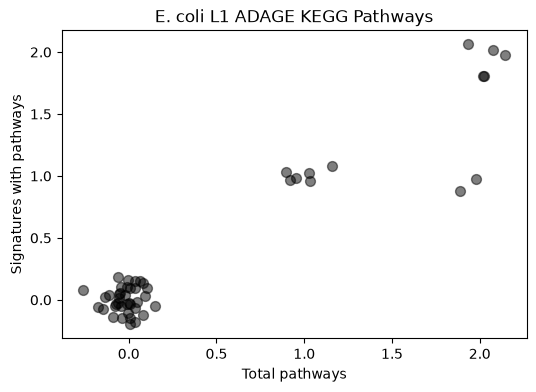

In [47]:
# Plot number of enriched KEGG pathways
plt.figure(figsize = (6, 4))
np.random.seed(42)

for df in kegg_dfs:
  x = ((df > 1.5).sum(axis = 0) > 0).sum()
  y = ((df > 1.5).sum(axis = 1) > 0).sum()

  # Add small jitter
  x_jittered = x + np.random.normal(0, 0.1)
  y_jittered = y + np.random.normal(0, 0.1)

  plt.scatter(
    x_jittered, 
    y_jittered,
    alpha = 0.5, 
    color = "black", 
    s = 50
  )

plt.title('E. coli L1 ADAGE KEGG Pathways')
plt.xlabel('Total pathways')
plt.ylabel('Signatures with pathways')

# Save figure locally
plot_path = '../data/ec_L1_kegg.png'
plt.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/L1 Models/plots/'

### Training Loss Curves

In [48]:
# Create a NumPy 2D array of losses, where each array is for each model
train_losses = np.array([
  model.history.history['loss']
  for model in loaded_models
])

val_losses = np.array([
  model.history.history['val_loss']
  for model in loaded_models
])

n_models, n_epochs = train_losses.shape
epochs = np.arange(n_epochs)

In [49]:
# Calculate median loss across models at each epoch
train_median = np.median(train_losses, axis=0)
val_median = np.median(val_losses, axis=0)

# Calculate 25th and 75th percentiles
train_q25, train_q75 = np.percentile(
  train_losses, [25, 75], axis=0
)
val_q25, val_q75 = np.percentile(
  val_losses, [25, 75], axis=0
)

# Calculate 10th and 90th percentiles
train_q10, train_q90 = np.percentile(
  train_losses, [10, 90], axis=0
)
val_q10, val_q90 = np.percentile(
  val_losses, [10, 90], axis=0
)

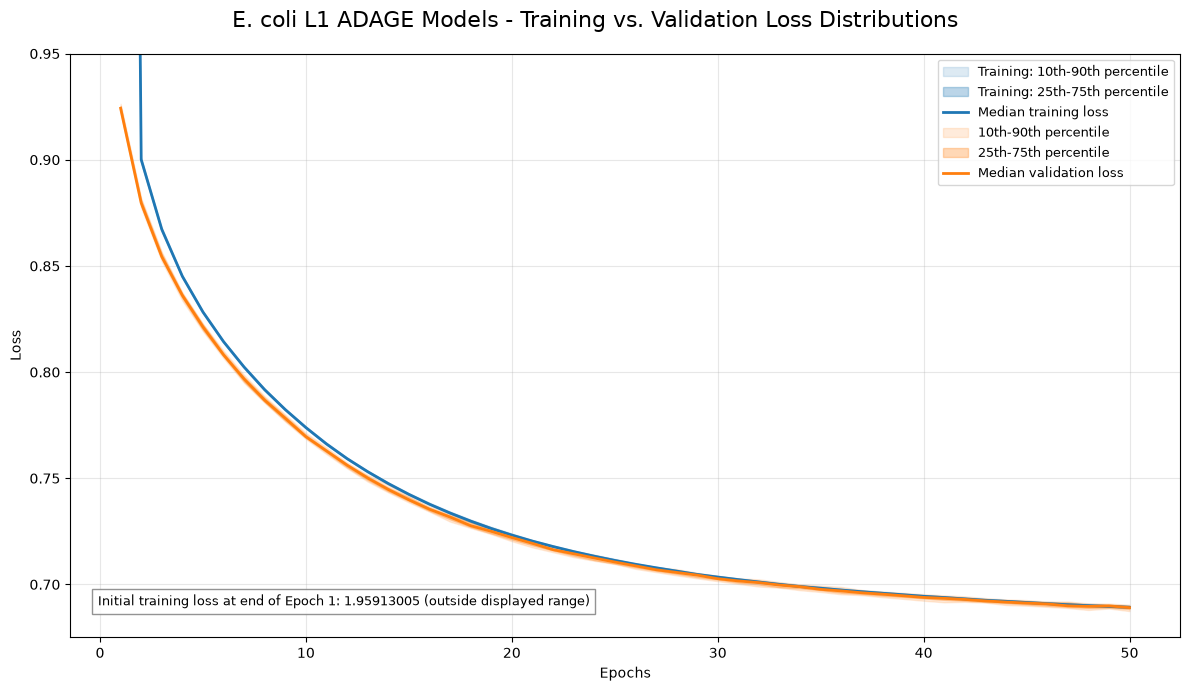

In [54]:
fig, ax = plt.subplots(figsize=(12, 7))

fig.suptitle(
  'E. coli L1 ADAGE Models - Training vs. Validation Loss Distributions',
  fontsize = 16
)
plt.style.use('tableau-colorblind10')

# *** Plot training loss *** #

# Plot 10th - 90th percentile outside
ax.fill_between(
  epochs + 1,
  train_q10,
  train_q90,
  color = 'tab:blue',
  alpha = 0.15,
  label = 'Training: 10th-90th percentile'
)

# Plot 25th - 75th percentile inside
ax.fill_between(
  epochs + 1,
  train_q25,
  train_q75,
  color = 'tab:blue',
  alpha = 0.3,
  label = 'Training: 25th-75th percentile'
)

# Median training loss
ax.plot(
  epochs + 1,
  train_median,
  color = 'tab:blue',
  linewidth = 2,
  label = 'Median training loss'
)

# *** Plot validation loss *** #

# Plot 10th - 90th percentile outside
ax.fill_between(
  epochs + 1,
  val_q10,
  val_q90,
  color = 'tab:orange',
  alpha = 0.15,
  label = '10th-90th percentile'
)

# Plot 25th - 75th percentile inside
ax.fill_between(
  epochs + 1,
  val_q25,
  val_q75,
  color = 'tab:orange',
  alpha = 0.3,
  label = '25th-75th percentile'
)

# Median validation loss
ax.plot(
  epochs + 1,
  val_median,
  color = 'tab:orange',
  linewidth = 2,
  label = 'Median validation loss'
)

ax.set(
  xlabel = 'Epochs',
  ylabel = 'Loss'
)
ax.grid(alpha = 0.3)

ax.legend(
    loc='best',
    fontsize=9
)

ax.set_ylim(0.675, 0.95)
ax.text(
  0.025, 
  0.05,
  'Initial training loss at end of Epoch 1: 1.95913005 (outside displayed range)',
  transform = ax.transAxes,
  fontsize = 9,
  ha = 'left',
  va = 'bottom',
  bbox = dict(
    facecolor = 'white',
    alpha = 0.85,
    edgecolor = 'gray'
  )
)

plt.tight_layout()

# Save figure locally
plot_path = '../data/ec_L1_loss_dist.png'
fig.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/L1 Models/plots/'

### Weight Distributions

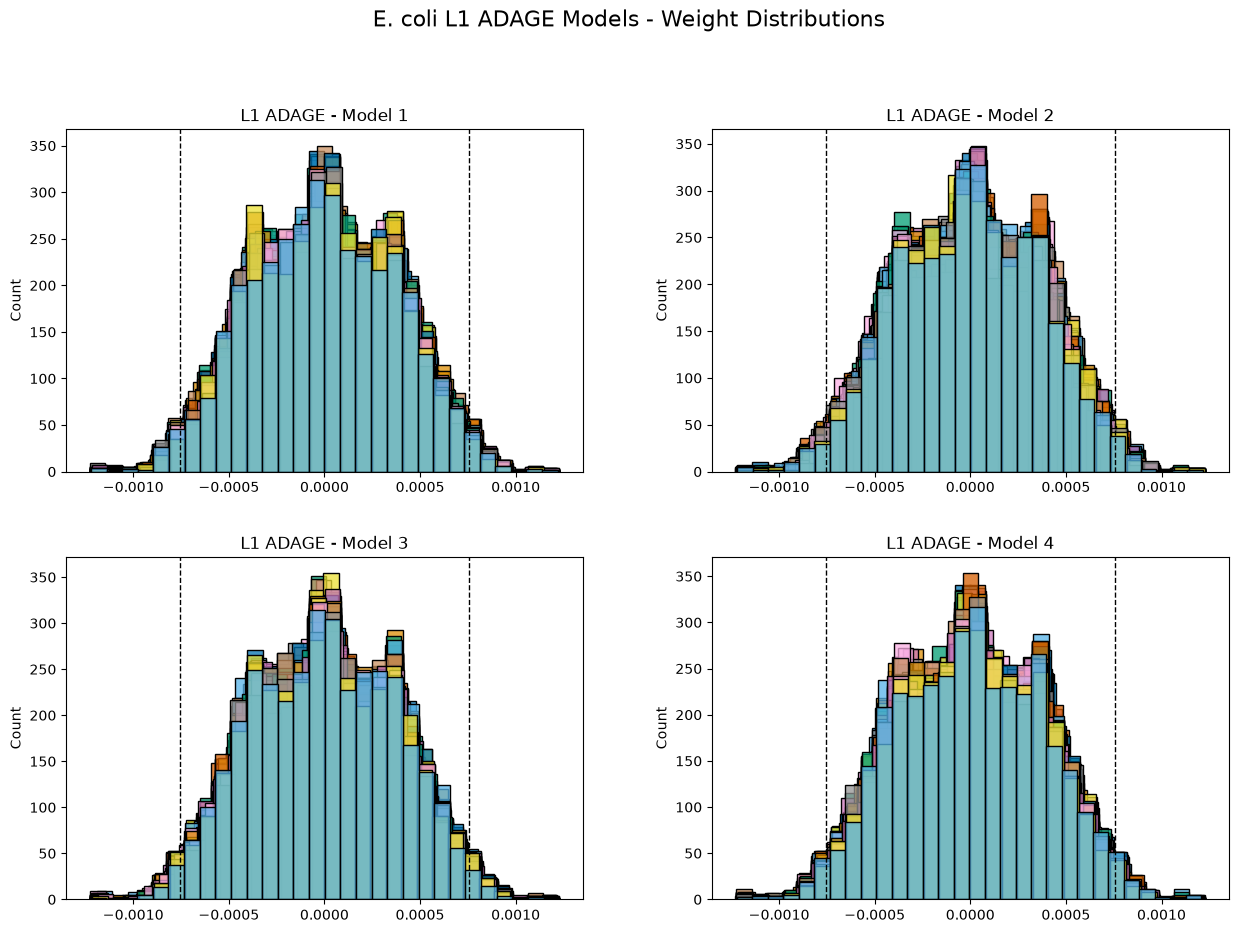

In [55]:
plot_titles = [
  f'L1 ADAGE - Model {i+1}'
  for i in range(4)
]

fig, ax = plt.subplots(2, 2, figsize = (15, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli L1 ADAGE Models - Weight Distributions',
  fontsize = 16,
  y = 1
)
colorblind_colors = sns.color_palette("colorblind")

for i in range(2):
  for j in range(2):
    weights_matrix = np.asarray(loaded_models[2*i + j].autoencoder.get_weights()[0])

    for node in range(optimal_hps['units']):
      weights = weights_matrix[:, node]
      weights = weights[np.isfinite(weights)]

      # Skip empty arrays and constant distributions
      if len(weights) == 0 or np.min(weights) == np.max(weights):
        continue

      # Each hidden node weight distribution
      sns.histplot(
        weights,
        ax = ax[i, j],
        bins = 30,
        color = colorblind_colors[node % len(colorblind_colors)],
        kde = False
      )

    all_weights = weights_matrix.flatten()
    all_weights = all_weights[np.isfinite(all_weights)]
    cutoff = np.std(all_weights) * 2

    ax[i, j].axvline(
      x = cutoff,
      color = 'black',
      linestyle = '--',
      linewidth = 1
    )
    ax[i, j].axvline(
      x = -cutoff,
      color = 'black',
      linestyle = '--',
      linewidth = 1
    )
    ax[i, j].set(title = plot_titles[2*i + j])

# Save figure locally
plot_path = '../data/ec_L1_weight_dist.png'
fig.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/L1 Models/plots/'